In [18]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Calculation of permittivity change with acoustic modes

Here, we focus on the contribution to $\sigma_{ext}(\lambda)$ :
$$\Delta \sigma_{ext}(\lambda) = \frac{\partial \sigma_{ext}}{\partial \varepsilon_1} \Delta \varepsilon_1 + \frac{\partial \sigma_{ext}}{\partial \varepsilon_2} \Delta \varepsilon_2$$

And then : 
$$ \Delta \varepsilon_1(\lambda) = \left( a^D(\lambda) + a^{ib}(\lambda) \right) \left( \frac{dV}{V} \right)$$
$$ \Delta \varepsilon_2(\lambda) = \left( b^D(\lambda) + b^{ib}(\lambda) \right) \left( \frac{dV}{V} \right)$$

## Interband contributions

First, we compute the interband part of permittivity :
$$ \varepsilon(\lambda) = \varepsilon^D(\lambda) + \varepsilon^{ib}(\lambda) - 1$$
$$\varepsilon^{ib}(\lambda) = 1 + (\varepsilon(\lambda) - \varepsilon^D(\lambda))$$

$$\Delta \varepsilon_2^{ib} = -\sum_m \frac{\partial \varepsilon^{ib}_{2, m}}{\partial \lambda} \Delta \lambda_{ib,m}$$

$$\Delta \lambda_{ib,m} = \frac{\partial \lambda_{ib,m}}{\partial V} \Delta V = \left( \frac{\partial \lambda_{ib,m}}{\partial T
} \cdot \frac{\partial T}{\partial V
}\right) \Delta V = \frac{\partial \lambda_{ib,m}}{\partial T} \frac{dV}{3\alpha V}$$

In [19]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname_eps1 = 'interband_permittivity_change_stoll_2014_eps1.csv'
fname_eps2 = 'interband_permittivity_change_stoll_2014_eps2.csv'


alpha = 1.42e-5 #in K-1

Data_interband ={}
Data_interband['eps1'] ={}
Data_interband['eps2'] ={}

os.chdir(dir_root)
f = pd.read_csv(fname_eps1,sep=";", decimal=",")
Data_interband['eps1']['lambda'] = (f['lambda'].__array__())
Data_interband['eps1']['eV'] = 1240/Data_interband['eps1']['lambda']
Data_interband['eps1']['Delta_eps1'] = f['Delta eps1 ib (1K)'].__array__()
Data_interband['eps1']['a_ib'] = Data_interband['eps1']['Delta_eps1']/(3*alpha)


os.chdir(dir_root)
f2 = pd.read_csv(fname_eps2,sep=";", decimal=",")
Data_interband['eps2']['lambda'] = (f2['lambda'].__array__())
Data_interband['eps2']['eV'] = 1240/Data_interband['eps2']['lambda']
Data_interband['eps2']['Delta_eps2'] = f2['Delta eps2 ib (1K)'].__array__()
Data_interband['eps2']['b_ib'] = Data_interband['eps2']['Delta_eps2']/(3*alpha)

## Compute eps2 for each band

In [20]:
# Get the eps2 extracted from Jhonson christy
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname = 'eps2_fit_Nathan_Olmon_SC.csv'
#fname = 'eps_2_interband.csv'


Data_eps2 = get_eps2_ib(dir_root, fname)


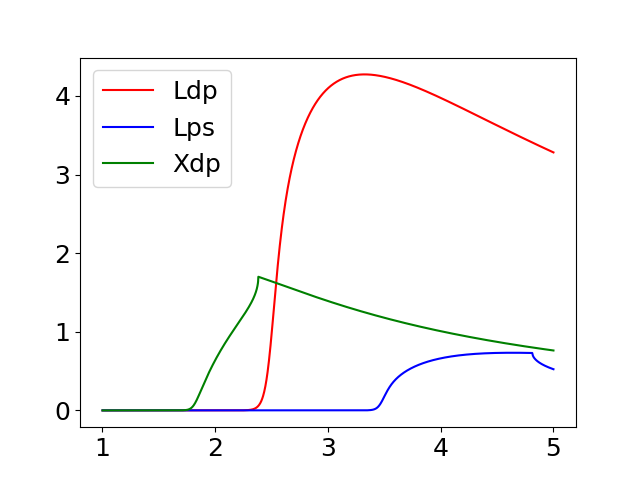

In [21]:
fig, ax = plt.subplots()

ax.plot(Data_eps2['eV'], Data_eps2['eps2_Ldp'], label = 'Ldp', color='red')
ax.plot(Data_eps2['eV'], Data_eps2['eps2_Lps'], label = 'Lps', color='blue')
ax.plot(Data_eps2['eV'], Data_eps2['eps2_Xdp'], label = 'Xdp', color='green')

ax.legend()


## Compute $\frac{\partial \varepsilon_{2, ib}}{\partial \lambda_{ib}}$

In [ ]:
sigma=50 #smoothing coeff for X transition

Permittivity_ib_variations = {}

Permittivity_ib_variations['eps2_Ldp_interp'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Ldp'], fill_value=0, kind='cubic', bounds_error=False)
Permittivity_ib_variations['eps2_Lps_interp'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Lps'], fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['eps2_Xdp_interp'] = sc.interpolate.interp1d(Data_eps2['eV'], sc.ndimage.gaussian_filter1d(Data_eps2['eps2_Xdp'],sigma=sigma), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['eps2_Xdp_interp_v2'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Xdp'], fill_value=0, kind='quadratic', bounds_error=False)

Energy = np.linspace(1, 4, 20000)
Permittivity_ib_variations['deps2_Ldp/deV'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_ib_variations['eps2_Ldp_interp'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps2_Lps/deV'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_ib_variations['eps2_Lps_interp'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps2_Xdp/deV'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_ib_variations['eps2_Xdp_interp'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps2_Xdp/deV_v2'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_ib_variations['eps2_Xdp_interp_v2'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)


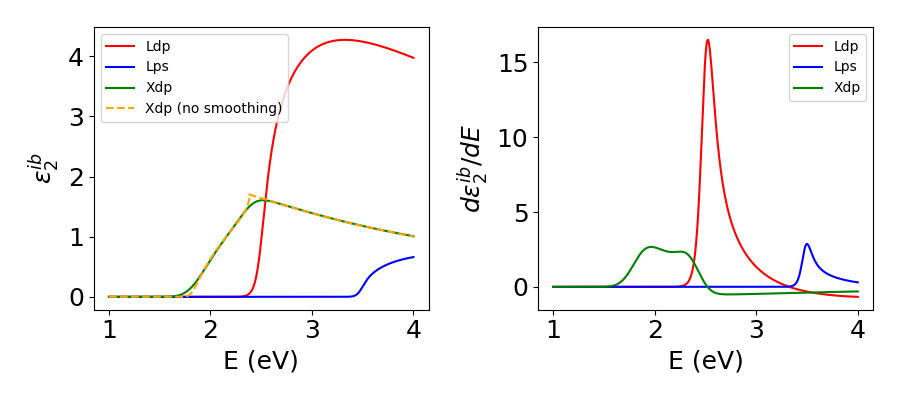

In [23]:

fig, ax = plt.subplots(ncols=2, figsize = (9,4))

ax[0].plot(Energy, Permittivity_ib_variations['eps2_Ldp_interp'](Energy), color='red', label='Ldp')
ax[0].plot(Energy, Permittivity_ib_variations['eps2_Lps_interp'](Energy), color='blue', label='Lps')
ax[0].plot(Energy, Permittivity_ib_variations['eps2_Xdp_interp'](Energy), color='green', label='Xdp')
ax[0].plot(Energy, Permittivity_ib_variations['eps2_Xdp_interp_v2'](Energy), color='orange', linestyle='--', label='Xdp (no smoothing)')
ax[0].legend(fontsize=10)
ax[0].set_ylabel(r'$\varepsilon_2^{ib}$')
ax[0].set_xlabel('E (eV)')

ax[1].plot(Energy, Permittivity_ib_variations['deps2_Ldp/deV'](Energy), color='red', label='Ldp')
ax[1].plot(Energy, Permittivity_ib_variations['deps2_Lps/deV'](Energy), color='blue', label='Lps')
#ax[1].plot(Energy, Permittivity_ib_variations['deps2_Xdp/deV_v2'](Energy), color='orange', label='Xdp (no smoothing)')
ax[1].plot(Energy, Permittivity_ib_variations['deps2_Xdp/deV'](Energy), color='green', label='Xdp')
ax[1].legend(fontsize=10)
ax[1].set_ylabel(r'$d\varepsilon_2^{ib}/dE$')
ax[1].set_xlabel('E (eV)')
plt.tight_layout()

## Convert it in $\Delta \varepsilon_{2, ib}$ contribution

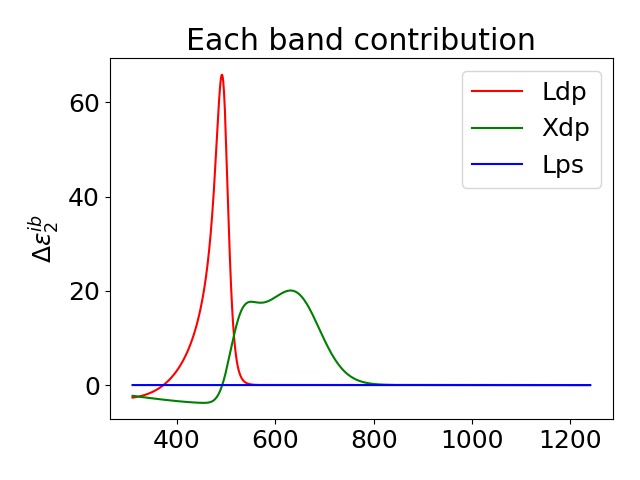

In [24]:
alpha = 1.42e-5 #in K-1

#Valeurs Stoll 2014
dwp_dT_Ldp = -1.7e-4 # for the d->p (L) transition, in eV/K
dwp_dT_Xdp = -3.2e-4 # for the d->p (X) transntion, in eV/K

#Valeurs Source stoll 2014 : Winsemius 1976
# dwp_dT_Ldp = -3e-4 # for the d->p (L) transition, in eV/K
# dwp_dT_Xdp = 0 # for the d->p (X) transntion, in eV/K

#dwp_dT_Xdp = 0 # for the d->p (X) transntion, in eV/K
#dwp_dT_Xdp = 0 # for the d->p (X) transntion, in eV/K
dwp_dT_Lps = 0  

#Mes valeurs ?
#dwp_dT_Ldp = -3e-4 # for the d->p (L) transition, in eV/K
#dwp_dT_Xdp = 0 # for the d->p (X) transntion, in eV/K

Delta_eps2_ib_Ldp = -Permittivity_ib_variations['deps2_Ldp/deV'](Energy) * dwp_dT_Ldp * 1/(3*alpha)
Delta_eps2_ib_Xdp = -Permittivity_ib_variations['deps2_Xdp/deV'](Energy) * dwp_dT_Xdp * 1/(3*alpha)
Delta_eps2_ib_Lps = -Permittivity_ib_variations['deps2_Lps/deV'](Energy) * dwp_dT_Lps * 1/(3*alpha)



Permittivity_ib_variations['deps2_Ldp'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Ldp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps2_Xdp'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Xdp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps2_Lps'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Lps, fill_value=0, kind='quadratic', bounds_error=False)




fig,ax = plt.subplots()

ax.plot(1240/Energy,  Permittivity_ib_variations['deps2_Ldp'](Energy), color='red', label = 'Ldp')
ax.plot(1240/Energy, Permittivity_ib_variations['deps2_Xdp'](Energy), color='green', label = 'Xdp')
ax.plot(1240/Energy, Delta_eps2_ib_Lps, color='blue', label = 'Lps')

ax.set_title('Each band contribution')
ax.set_ylabel(r'$\Delta \varepsilon_2^{ib}$')
ax.legend()
plt.tight_layout()

C:\Users\nberr\AppData\Local\Temp\ipykernel_18152\2336350198.py:1: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



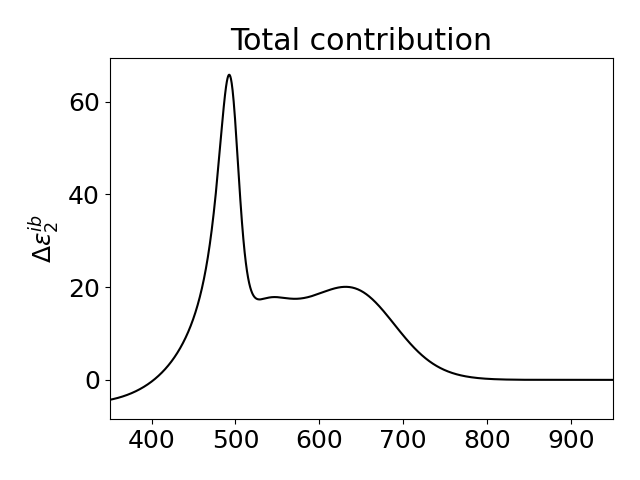

In [25]:
fig,ax = plt.subplots()

ax.plot(1240/Energy, (Delta_eps2_ib_Xdp + Delta_eps2_ib_Ldp), color='black')

ax.set_ylabel(r'$\Delta \varepsilon_2^{ib}$')
ax.set_xlim((350, 950))
ax.set_title('Total contribution')
plt.tight_layout()

## Compute $\Delta \varepsilon_{1, ib}$ for each band

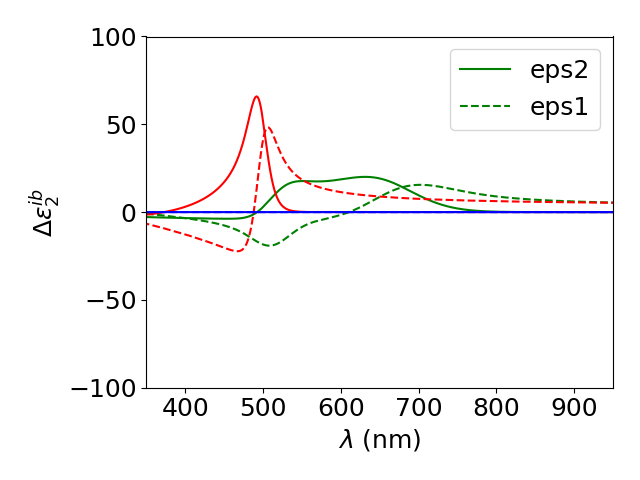

In [36]:
Delta_eps2_ib_tot = (Delta_eps2_ib_Xdp + Delta_eps2_ib_Ldp)

W = Energy/sc.constants.hbar

Delta_eps1_ib_Ldp = elli.kkr.kkr.im2re(Delta_eps2_ib_Ldp, W)
Delta_eps1_ib_Xdp = elli.kkr.kkr.im2re(Delta_eps2_ib_Xdp, W)
Delta_eps1_ib_Lps = elli.kkr.kkr.im2re(Delta_eps2_ib_Lps, W)


Permittivity_ib_variations['deps1_Ldp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Ldp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps1_Lps'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Lps, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_ib_variations['deps1_Xdp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Xdp, fill_value=0, kind='quadratic', bounds_error=False)


Delta_eps1_ib_tot = elli.kkr.kkr.im2re(Delta_eps2_ib_tot, W)

fig,ax = plt.subplots()

ax.plot(1240/Energy, Permittivity_ib_variations['deps2_Xdp'](Energy), color='green', label='eps2')
ax.plot(1240/(W*sc.constants.hbar), Permittivity_ib_variations['deps1_Xdp'](Energy), color='green', label = 'eps1', linestyle='--')

ax.plot(1240/Energy, Delta_eps2_ib_Ldp, color='red')
ax.plot(1240/(W*sc.constants.hbar), Delta_eps1_ib_Ldp, color='red',  linestyle='--')

ax.plot(1240/Energy, Delta_eps2_ib_Lps, color='blue')
ax.plot(1240/(W*sc.constants.hbar), Delta_eps1_ib_Lps, color='blue', linestyle='--')


ax.set_ylabel(r'$\Delta \varepsilon_2^{ib}$')
ax.set_xlabel(r'$\lambda$ (nm)')
ax.set_xlim((350, 950))
ax.set_ylim((-100, 100))
ax.legend()
plt.tight_layout()


look at the integrand

In [27]:
if 0 : 
    Delta_eps2_ib = (Delta_eps2_ib_Xdp + Delta_eps2_ib_Ldp)

    W = Energy/sc.constants.hbar
    Delta_eps1_ib = elli.kkr.kkr.im2re(Delta_eps2_ib, W)


    idx = 3000
    fig,ax = plt.subplots()
    integrande = W*Delta_eps2_ib/(W**2 - W[idx]**2)
    ax.plot(1240/(W*sc.constants.hbar), np.log(np.abs(integrande)), color='black',)
    #ax.plot(W, Delta_eps2_ib, color='red',)
    ax.axvline((1240/(W[idx]*sc.constants.hbar)))
    ax.set_ylabel(r'$\Delta \varepsilon_2^{ib} (10^{-3})$')
    plt.tight_layout()


## Get the plasmonic derivatives on my ND

In [28]:
ND_names = ['Sapphire 2,3 - NDd zone 3', 'Silice thick 4,5 - D1 zone1', 'Membrane 3,5 - ND3,5-5']
Lda_SPR_data = {}
Lda_SPR_data['Sapphire 2,3 - NDd zone 3'] = 638
Lda_SPR_data['Silice thick 4,5 - D1 zone1'] = 624
Lda_SPR_data['Membrane 3,5 - ND3,5-5'] = 599


Lda_min_meas = {}
Lda_min_meas['Sapphire 2,3 - NDd zone 3'] = 580
Lda_min_meas['Silice thick 4,5 - D1 zone1'] = 570
Lda_min_meas['Membrane 3,5 - ND3,5-5'] = 540


Lda_max_meas = {}
Lda_max_meas['Sapphire 2,3 - NDd zone 3'] = 720
Lda_max_meas['Silice thick 4,5 - D1 zone1'] = 700
Lda_max_meas['Membrane 3,5 - ND3,5-5'] = 650


global_dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'

All_data = {}



for key in ND_names :
    print(key)
    All_data[key] = {}
    dir_plasmonic = '\\'.join((global_dir_root, key, 'Optical sensitivity calculation'))
    All_data[key]['plasmonic_derivative'] = get_plasmonic_derivatives(dir_plasmonic, 'plasmonic_derivatives.csv')
    All_data[key]['lda_SPR'] = Lda_SPR_data[key]
    All_data[key]['lda_meas_min'] = Lda_min_meas[key]
    All_data[key]['lda_meas_max'] = Lda_max_meas[key]

Plasmon_derivatives = {}

for key in ND_names :
    Plasmon_derivatives[key] = {}

    Plasmon_derivatives[key]['ds_deps1'] = sc.interpolate.interp1d(All_data[key]['plasmonic_derivative']['lambda'], All_data[key]['plasmonic_derivative']['dsigma/deps1'], fill_value=0, kind='quadratic', bounds_error=False)
    Plasmon_derivatives[key]['ds_deps2'] = sc.interpolate.interp1d(All_data[key]['plasmonic_derivative']['lambda'], All_data[key]['plasmonic_derivative']['dsigma/deps2'], fill_value=0, kind='quadratic', bounds_error=False)



Sapphire 2,3 - NDd zone 3
Silice thick 4,5 - D1 zone1
Membrane 3,5 - ND3,5-5


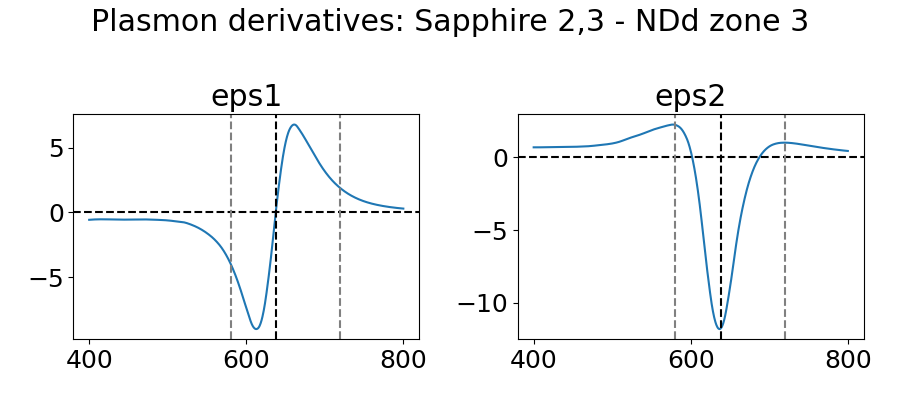

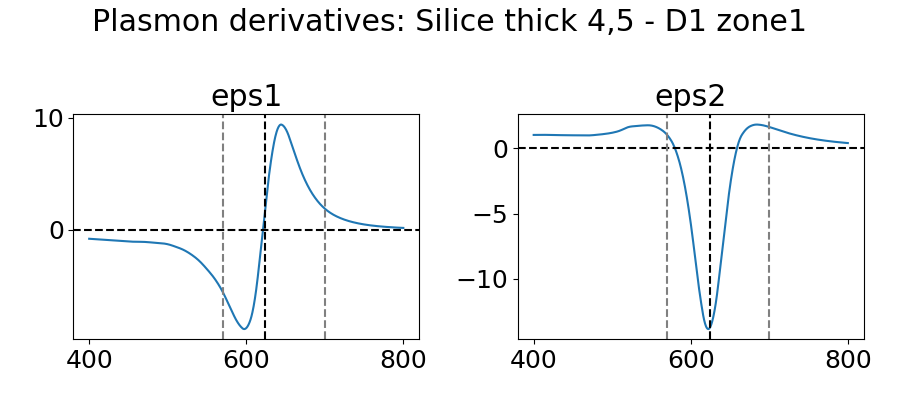

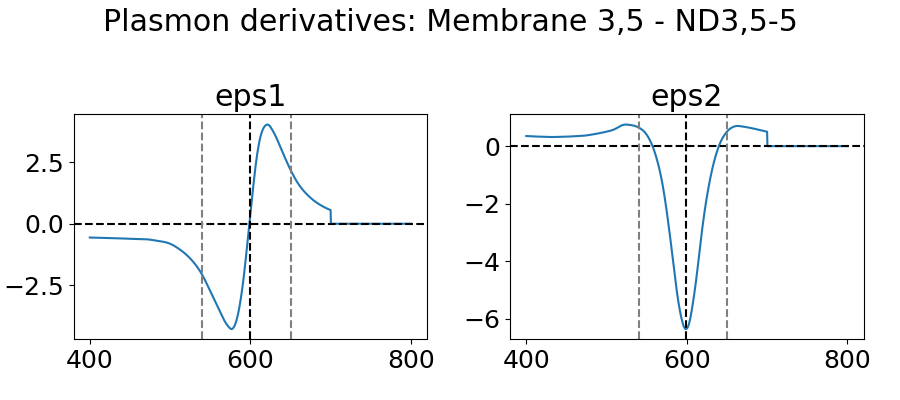

In [29]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :

    plasmon_deriv = Plasmon_derivatives[key]

    fig, ax = plt.subplots(ncols=2, figsize=(9,4))

    fig.suptitle('Plasmon derivatives: ' + key)

    ax[0].plot(Lambda, plasmon_deriv['ds_deps1'](Lambda))
    ax[0].set_title('eps1')
    
    ax[1].plot(Lambda, plasmon_deriv['ds_deps2'](Lambda))
    ax[1].set_title('eps2')

    ax[0].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[1].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')


    ax[0].axhline(0, linestyle='--', color='black')
    ax[1].axhline(0, linestyle='--', color='black')

    ax[0].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    

    ax[0].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
  

    plt.tight_layout()

In [30]:
#Gold values from Romain PhD manuscript
w_p = 9.01 * sc.constants.e / sc.constants.hbar 
gamma_0 = 70*1e-3 * sc.constants.e / sc.constants.hbar


def eps_1_drude(w, gamma=gamma_0, w_p=w_p) :
    return(1 - (w_p**2)/(w**2+gamma**2))

def eps_2_drude(w, gamma=gamma_0, w_p=w_p) :
    return((gamma*w_p**2)/(w*(w**2 + gamma**2)))


def a_drude(w) :
    return (1- eps_1_drude(w))

def b_drude(w) :
    return(-eps_2_drude(w))

# in rad/s
def a_drude_rad(w) :
    return (1- eps_1_drude(w))
def b_drude_rad(w) :
    return(-eps_2_drude(w))

# in eV
def a_drude_ernergy(energy) :
    return (1- eps_1_drude(energy* sc.constants.e / sc.constants.hbar  ))
def b_drude_ernergy(energy) :
    return(-eps_2_drude(energy * sc.constants.e / sc.constants.hbar ))

# in nanometers
def a_drude_wavelength(lda) :
    return (1- eps_1_drude(2*np.pi*sc.constants.c /(lda*1e-9)))
def b_drude_wavelength(lda) :
    return(-eps_2_drude(2*np.pi*sc.constants.c /(lda*1e-9)))

## Calculate drude and interband contribution to sigma-ext change

In [31]:
eps_var = {}

for key in ND_names :


    plasmon_deriv = Plasmon_derivatives[key]
    
    eps1_var_Drude = plasmon_deriv['ds_deps1'](Lambda) * a_drude_wavelength(Lambda)
    eps2_var_Drude = plasmon_deriv['ds_deps2'](Lambda) * b_drude_wavelength(Lambda)

    eps1_var_ib = plasmon_deriv['ds_deps1'](Lambda) * (Permittivity_ib_variations['deps1_Ldp'](1240/Lambda) + Permittivity_ib_variations['deps1_Xdp'](1240/Lambda))
    eps2_var_ib = plasmon_deriv['ds_deps2'](Lambda) * (Permittivity_ib_variations['deps2_Ldp'](1240/Lambda) + Permittivity_ib_variations['deps2_Xdp'](1240/Lambda))
    
    eps1_var_ib = plasmon_deriv['ds_deps1'](Lambda) * (Permittivity_ib_variations['deps1_Ldp'](1240/Lambda) + Permittivity_ib_variations['deps1_Lps'](1240/Lambda) + Permittivity_ib_variations['deps1_Xdp'](1240/Lambda))
    eps2_var_ib = plasmon_deriv['ds_deps2'](Lambda) * (Permittivity_ib_variations['deps2_Ldp'](1240/Lambda) + Permittivity_ib_variations['deps2_Lps'](1240/Lambda) + Permittivity_ib_variations['deps2_Xdp'](1240/Lambda))

    eps_var[key] = {}
    eps_var[key]['eps1_drude'] = eps1_var_Drude
    eps_var[key]['eps2_drude'] = eps2_var_Drude

    eps_var[key]['eps1_ib'] = eps1_var_ib
    eps_var[key]['eps2_ib'] = eps2_var_ib

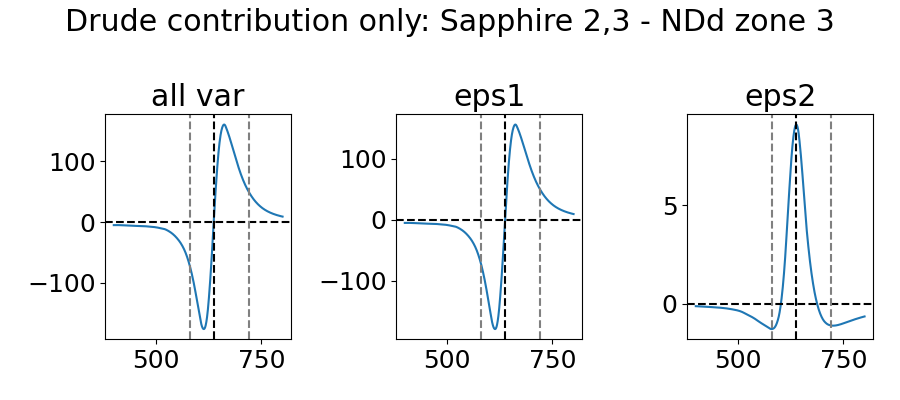

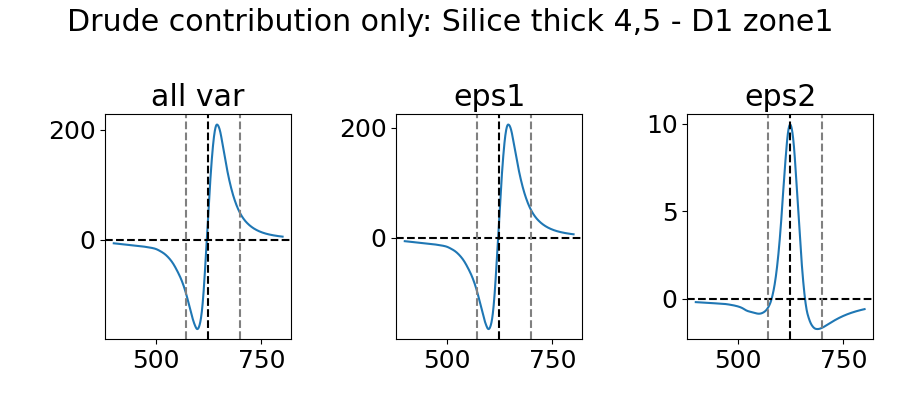

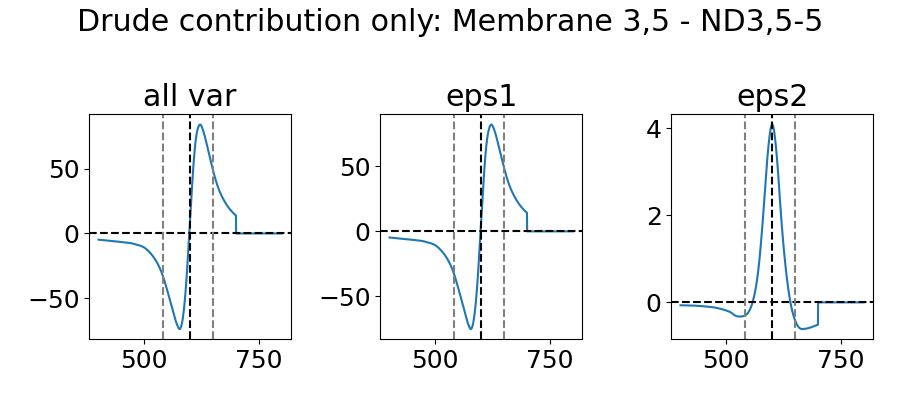

In [32]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :

    plasmon_deriv = Plasmon_derivatives[key]

    fig, ax = plt.subplots(ncols=3, figsize=(9,4))

    fig.suptitle('Drude contribution only: ' + key)

    
    ax[0].plot(Lambda, eps_var[key]['eps1_drude'] + eps_var[key]['eps2_drude'])
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps_var[key]['eps1_drude'])
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps_var[key]['eps2_drude'])
    ax[2].set_title('eps2')

    #show central SPR wavelength
    ax[0].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[1].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[2].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')


    ax[0].axhline(0, linestyle='--', color='black')
    ax[1].axhline(0, linestyle='--', color='black')
    ax[2].axhline(0, linestyle='--', color='black')

    ax[0].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')


    ax[0].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')

    plt.tight_layout()

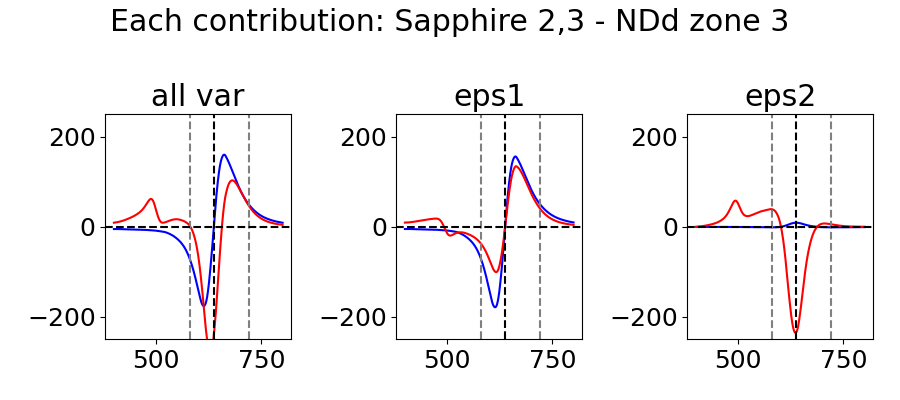

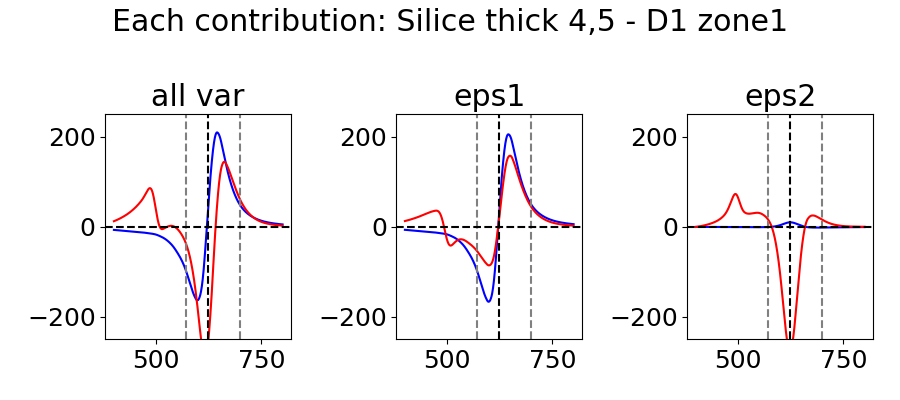

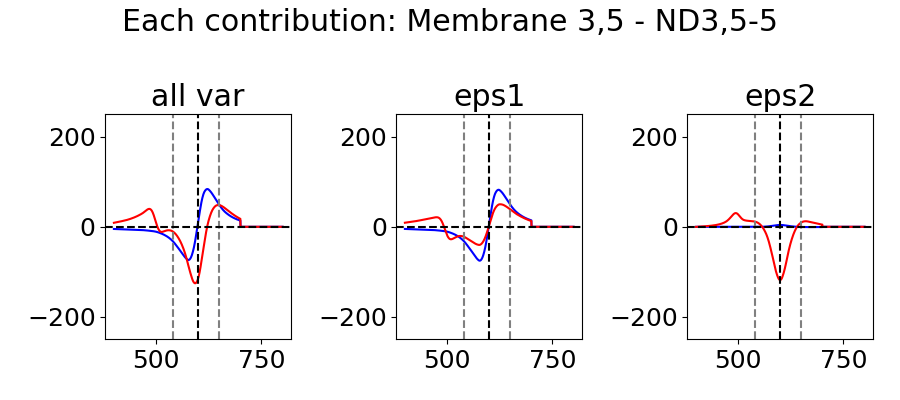

In [33]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :


    plasmon_deriv = Plasmon_derivatives[key]
    fig, ax = plt.subplots(ncols=3, figsize=(9,4))
    fig.suptitle('Each contribution: ' + key)
 
    ax[0].plot(Lambda, eps_var[key]['eps1_drude'] + eps_var[key]['eps2_drude'], color='blue', label='Drude')
    ax[0].plot(Lambda, eps_var[key]['eps1_ib'] + eps_var[key]['eps2_ib'], color='red', label='ib')
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps_var[key]['eps1_drude'], color='blue', label='Drude')
    ax[1].plot(Lambda, eps_var[key]['eps1_ib'], color='red', label='ib')
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps_var[key]['eps2_drude'], color='blue', label='Drude')
    ax[2].plot(Lambda, eps_var[key]['eps2_ib'], color='red', label='ib')
    ax[2].set_title('eps2')

    #show central SPR wavelength
    ax[0].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[1].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[2].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')


    ax[0].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')


    ax[0].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')

    ax[0].axhline(0, linestyle='--', color='black')
    ax[1].axhline(0, linestyle='--', color='black')
    ax[2].axhline(0, linestyle='--', color='black')


    ax[0].set_ylim((-250, 250))
    ax[1].set_ylim((-250, 250))
    ax[2].set_ylim((-250, 250))
    plt.tight_layout()

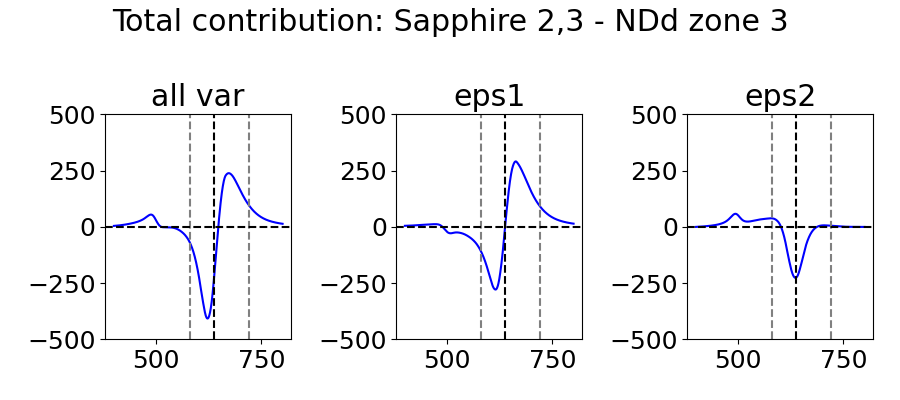

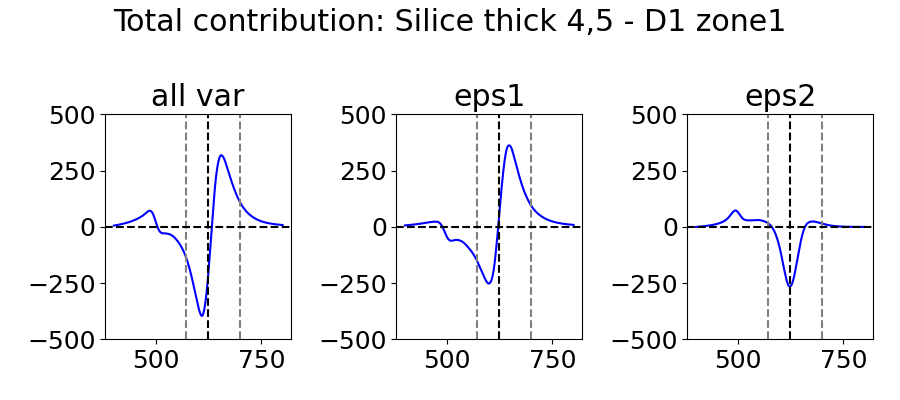

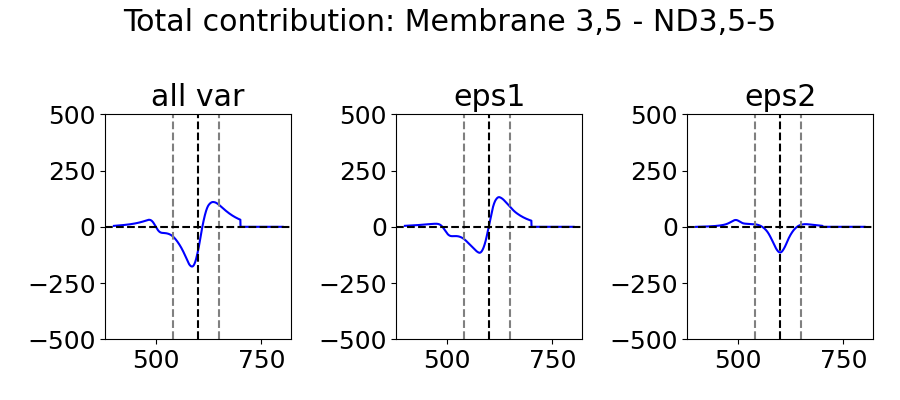

In [34]:
Lambda = np.linspace(400, 800, 1000)

for key in ND_names :


    plasmon_deriv = Plasmon_derivatives[key]
    fig, ax = plt.subplots(ncols=3, figsize=(9,4))
    fig.suptitle('Total contribution: ' + key)

    ax[0].plot(Lambda, eps_var[key]['eps1_drude']+eps_var[key]['eps2_drude'] + eps_var[key]['eps1_ib']+eps_var[key]['eps2_ib'], color='blue')
    ax[0].set_title('all var')

    ax[1].plot(Lambda, eps_var[key]['eps1_drude'] + eps_var[key]['eps1_ib'], color='blue')
    ax[1].set_title('eps1')
    
    ax[2].plot(Lambda, eps_var[key]['eps2_drude'] + eps_var[key]['eps2_ib'], color='blue')
    ax[2].set_title('eps2')

    #show central SPR wavelength
    ax[0].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[1].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')
    ax[2].axvline(All_data[key]['lda_SPR'], linestyle='--', color='black')


    ax[0].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_min'], linestyle='--', color='grey')


    ax[0].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[1].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')
    ax[2].axvline(All_data[key]['lda_meas_max'], linestyle='--', color='grey')

    ax[0].axhline(0, linestyle='--', color='black')
    ax[1].axhline(0, linestyle='--', color='black')
    ax[2].axhline(0, linestyle='--', color='black')


    ax[0].set_ylim((-500, 500))
    ax[1].set_ylim((-500, 500))
    ax[2].set_ylim((-500, 500))
    plt.tight_layout()